In [64]:
import glob
import numpy as np
import xarray as xr
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.stats import linregress
mm = 1 / 25.4
mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 9,
    "axes.labelsize": 8,
    "axes.titlesize": 8,
    "xtick.labelsize": 7.5,
    "ytick.labelsize": 7.5,
    "legend.fontsize": 8,
    "axes.linewidth": 0.5,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.major.size": 2.5,
    "ytick.major.size": 2.5,
    "lines.linewidth": 0.8,
    "axes.spines.top": True,
    "axes.spines.right": True,
    "pdf.fonttype": 42,   # editable text in Illustrator
    "ps.fonttype": 42,
    "savefig.dpi": 600,
})


In [13]:
mpl.rcdefaults()

In [2]:
p = "/glade/derecho/scratch/adixit/India_Heatwave/DATA/era5_data/"
box = dict(latitude=slice(30, 22), longitude=slice(75, 85))
period = slice("2024-05-01", "2024-06-30")
events = {"E1": slice("2024-05-25", "2024-06-01"),
          "E2": slice("2024-06-10", "2024-06-20")}

In [40]:
def anomaly(var, how="mean", ncvar=None):
    # var = folder / filename prefix; ncvar = variable name inside the files (defaults to var)
    files = sorted(glob.glob(f"{p}{var}/{var.lower()}.*.era5.nc"))
    da = xr.open_mfdataset(files)[ncvar or var].sel(**box).mean(("latitude", "longitude"))
    # collapse to daily (no-op for daily data); "max" gives the afternoon peak for PBLH
    da = da.assign_coords(md=("time", da.time.dt.strftime("%m-%d").values))
    clim = da.sel(time=slice("1980", "2020")).groupby("md").mean("time")
    return (da.sel(time="2024").groupby("md") - clim).compute()

In [41]:
cloud = anomaly("TCC") * 100
sw = anomaly("MSDWSWRF")
pblh = anomaly("PBLH", how="max", ncvar="BLH")
cloud_p, sw_p, pblh_p = (x.sel(time=period) for x in (cloud, sw, pblh))

SMOOTH_DAYS = 5
smooth = lambda x: x.rolling(time=SMOOTH_DAYS, center=True, min_periods=1).mean().sel(time=period)
pblh_s, cloud_s, sw_s = smooth(pblh), smooth(cloud), smooth(sw)

In [77]:
series = [
    (pblh_p, pblh_s,   "Boundary-layer height anomaly\n(m)"),
    (cloud_p, cloud_s, "Cloud-cover anomaly (%)"),
    (sw_p, sw_s,       "Downward shortwave anomaly\n(W m$^{-2}$)"),
]

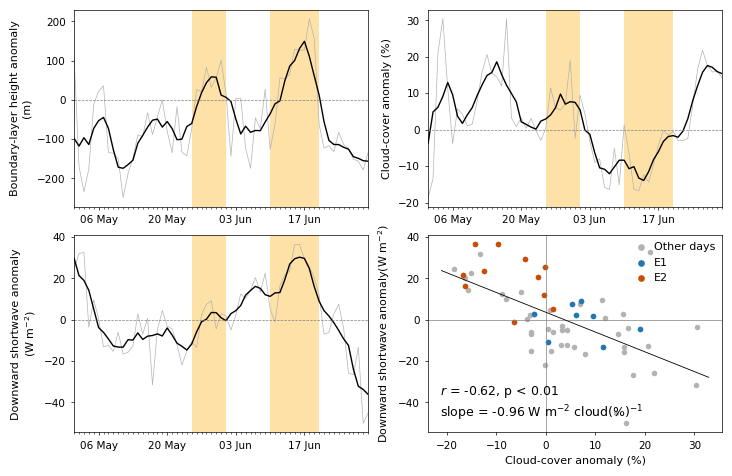

In [83]:
fig, axs = plt.subplots(2, 2, figsize=(183 * mm, 118 * mm),constrained_layout=True)

COL = {"E1": "#fec44f", "E2": "#fec44f"}   # Okabe-Ito, colour-blind safe
GREY = "#B3B3B3"

for ax, (raw, sm, ylabel) in zip(axs.flat[:3], series):
    ax.plot(raw.time, raw, color="0.7", lw=0.5)           # daily values
    ax.plot(sm.time, sm, color="black", lw=1.0)            # 5-day running mean
    ax.axhline(0, color="0.5", ls="--", lw=0.5)
    for name, ts in events.items():
        x0, x1 = np.datetime64(ts.start), np.datetime64(ts.stop)
        ax.axvspan(x0, x1, color=COL[name], alpha=0.5, lw=0)

    ax.set_ylabel(ylabel)
    ax.set_xlim(np.datetime64("2024-05-01"), np.datetime64("2024-06-30"))
    ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO, interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    ax.xaxis.set_minor_locator(mdates.DayLocator(interval=1))
    ax.tick_params(axis="x", which="minor", length=1.2, width=0.4)


COL = {"E1": "#1f78b4", "E2": "#cc4c02"}

ax = axs[1, 1]
ax.scatter(cloud_p, sw_p, s=16, color=GREY, lw=0, label="Other days", zorder=1)
for name, ts in events.items():
    ax.scatter(cloud_p.sel(time=ts), sw_p.sel(time=ts), s=16,color=COL[name], lw=0, label=name, zorder=2)

'''
# least-squares fit across the whole period
slope, icpt = np.polyfit(cloud_p.values, sw_p.values, 1)
r = np.corrcoef(cloud_p.values, sw_p.values)[0, 1]
xx = np.array(ax.get_xlim())
ax.plot(xx, slope * xx + icpt, color="black", lw=0.6, zorder=3)
ax.text(0.04, 0.05, f"$r$ = {r:.2f}\nslope = {slope:.1f} W m$^{{-2}}$ pp$^{{-1}}$",
        transform=ax.transAxes, fontsize=8, va="bottom")
'''

slope, icpt, r, p, _ = linregress(cloud_p.values, sw_p.values)
xx = np.array(ax.get_xlim())
ax.plot(xx, slope * xx + icpt, color="black", lw=0.6, zorder=3)
ax.text(0.04, 0.05, f"$r$ = {r:.2f}, p < 0.01\nslope = {slope:.2f} W m$^{{-2}}$ cloud(%)$^{{-1}}$",
        transform=ax.transAxes, fontsize=9, va="bottom")

ax.axhline(0, color="0.5", lw=0.5)
ax.axvline(0, color="0.5", lw=0.5)
ax.set_xlabel("Cloud-cover anomaly (%)")
ax.set_ylabel("Downward shortwave anomaly(W m$^{-2}$)")
ax.legend(frameon=False, loc="upper right", handletextpad=0.2,borderaxespad=0.2, markerscale=1.2)
plt.savefig('Cloud-cover.pdf', dpi=300, format='pdf', transparent=True)